# Multi-Class Intrusion Detection (NSL-KDD)

## 0. Introduction

Network intrusion detection is an important component of cybersecurity, helping identify malicious activities that may threaten the confidentiality, integrity, and availability of computer systems. However, detecting different types of attacks can be challenging, particularly when some attack categories are represented by very few examples.

This project uses the NSL-KDD dataset to develop a multi-class classification model that distinguishes normal network connections from four categories of attacks: denial of service (DoS), probing, remote-to-local (R2L), and user-to-root (U2R). The original attack labels are grouped into these broader categories to support the classification task.

Logistic Regression is used as a baseline model and compared with Random Forest. The analysis focuses not only on overall classification performance but also on the models' ability to identify minority attack classes. A custom decision-threshold approach is subsequently explored to investigate whether detection recall for U2R attacks can be improved.

By comparing model performance and examining the trade-off between precision and recall, this project demonstrates how class imbalance and decision thresholds can influence machine-learning-based intrusion detection.

## 1. Load Data

In [1]:
import pandas as pd

df = pd.read_csv('nsl_kdd.csv', header=None, index_col=0)

df.head()

,1,2,3,4,5,6,7,8,9,10,...,34,35,36,37,38,39,40,41,42,43
0,,,,,,,,,,,,,,,,,,,,,
NaN,0,1,2,3,4,5,6,7,8,9,...,33.00,34.00,35.00,36.00,37.00,38.00,39.00,40.00,41,42
0.0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20
1.0,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15
2.0,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19
3.0,0,tcp,http,SF,232,8153,0,0,0,0,...,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21


## 2. Assign Column Names

In [2]:
columns = [
    'duration', 'protocol_type', 'service',
    'flag', 'src_bytes', 'dst_bytes',
    'land', 'wrong_fragment', 'urgent',
    'hot', 'num_failed_logins',
    'logged_in', 'num_compromised',
    'root_shell', 'su_attempted',
    'num_root', 'num_file_creations',
    'num_shells', 'num_access_files',
    'num_outbound_cmds', 'is_host_login', 'is_guest_login',
    'count', 'srv_count', 'serror_rate', 'srv_serror_rate',
    'rerror_rate', 'srv_rerror_rate', 'same_srv_rate', 'diff_srv_rate',
    'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count',
    'dst_host_same_srv_rate', 'dst_host_diff_srv_rate',
    'dst_host_same_src_port_rate', 'dst_host_srv_diff_host_rate',
    'dst_host_serror_rate', 'dst_host_srv_serror_rate',
    'dst_host_rerror_rate', 'dst_host_srv_rerror_rate',
    'label', 'difficulty'
]

df.columns = columns

## 3. Map Labels to Attack Categories

In [3]:
attack_mapping = {
    # DoS
    'neptune': 'dos', 
    'smurf': 'dos',
    'back': 'dos',
    'teardrop': 'dos',
    'pod': 'dos',
    'land': 'dos',

    # Probe
    'ipsweep': 'probe',
    'nmap': 'probe',
    'portsweep': 'probe',
    'satan': 'probe',

    # R2L
    'ftp_write': 'r2l',
    'guess_passwd': 'r2l',
    'imap': 'r2l',
    'multihop': 'r2l',
    'phf': 'r2l',
    'spy': 'r2l',
    'warezclient': 'r2l',
    'warezmaster': 'r2l',

    # U2R
    'buffer_overflow': 'u2r',
    'loadmodule': 'u2r',
    'perl': 'u2r',
    'rootkit': 'u2r'
}

In [4]:
def map_attack(label):
    
    label = label.replace('.', '') #remove trailing dot

    if label=='normal':
        return 'normal'
    return attack_mapping.get(label, 'other')

df['target'] = df['label'].apply(map_attack)

## 4. Check Distribution of Target

In [5]:
print(df['target'].value_counts())

target
normal    67343
dos       45927
probe     11656
r2l         995
u2r          52
other         1
Name: count, dtype: int64


## 5. Drop Unnecessary Columns

In [6]:
df = df.drop(columns=['label', 'difficulty'])

## 6. One-Hot Encode Categorical Features

In [7]:
df = pd.get_dummies(df, columns=['protocol_type', 'service', 'flag'], drop_first=True)

## 7. Define Features and Target

The dataset contains an 'other' category with only a single instance. This class will be removed prior to model training for three reasons:

(1) stratified train-test splitting requires at least two samples per class;
(2) a single instance does not provide sufficient data for the model to learn meaningful patterns; and
(3) performance on such a class cannot be reliably evaluated.

Removing this class ensures a valid and statistically sound modeling pipeline while preserving all meaningful attack categories.

In [8]:
# removing 'other' from target column
df = df[df['target'] != 'other']

x = df.drop(columns=['target'])
y = df['target']

## 8. Train-Test Split

In [9]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, stratify=y, random_state=42)

## 9. Feature Scaling

In [10]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

## 10. Train Logistic Regression (Baseline)

In [11]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000, class_weight='balanced')

model.fit(x_train_scaled, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


## 11. Predictions

In [12]:
y_pred = model.predict(x_test_scaled)

## 12. Evaluate Logistic Regression (Baseline)

In [13]:
# classification report

from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

print('Logistic Regression Baseline Model Accuracy: ', accuracy_score(y_test, y_pred))

print(classification_report(y_test, y_pred))

Logistic Regression Baseline Model Accuracy:  0.9672682049110923
              precision    recall  f1-score   support

         dos       1.00      1.00      1.00     13778
      normal       1.00      0.94      0.97     20203
       probe       0.92      0.98      0.95      3497
         r2l       0.31      0.94      0.47       298
         u2r       0.06      0.75      0.11        16

    accuracy                           0.97     37792
   macro avg       0.66      0.92      0.70     37792
weighted avg       0.98      0.97      0.97     37792



[[13753    21     4     0     0]
 [   48 19072   284   620   179]
 [    6    39  3437     6     9]
 [    0     7     0   281    10]
 [    0     3     0     1    12]]


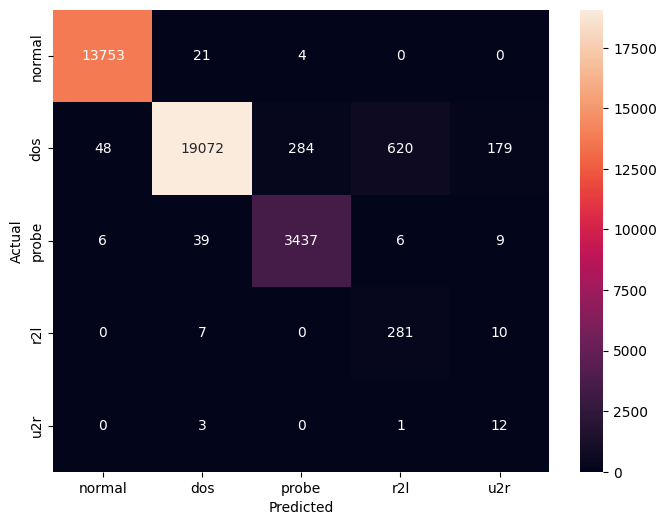

In [14]:
# confusion matrix

import seaborn as sns
import matplotlib.pyplot as plt

labels = ['normal', 'dos', 'probe', 'r2l', 'u2r']

cm = confusion_matrix(y_test, y_pred)

print(cm)

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=labels, yticklabels=labels)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

## 13. Interpretation for Logistic Regression Baseline Model

The model demonstrates strong overall performance, achieving high accuracy and excellent classification results for majority classes such as *dos*, *normal*, and *probe*. These classes exhibit high precision, recall, and F1-scores, indicating that the model has successfully learned their underlying patterns.

However, performance on minority classes (*r2l* and *u2r*) is significantly weaker. While recall remains relatively high, precision is extremely low, particularly for *u2r*. This indicates that the model tends to over-predict these rare attack classes, resulting in a high number of false positives.

As a result, although the model is effective at detecting most instances of rare attacks, its predictions for these classes are not reliable. This highlights the impact of class imbalance and suggests that the model provides an accurate representation for majority classes but a less reliable one for minority classes.

These findings emphasize the importance of evaluating models beyond overall accuracy, particularly in imbalanced cybersecurity datasets where minority classes are often of greater importance.

Unlike weighted recall, weighted precision does not simplify to overall accuracy because it depends on the number of predicted samples per class (TP + FP), which varies based on model behavior. 

As a result, weighted precision is influenced more heavily by majority classes and may obscure poor performance on minority classes, as observed with the *u2r* category in this project.

The F1-score provides a more balanced evaluation of model performance by considering both precision and recall. 

In this project, rare classes such as *u2r* exhibit high recall but extremely low precision, resulting in a low F1-score. This indicates that while the model detects most instances of these attacks, it does so unreliably, producing a high number of false positives.

Therefore, F1-score is a more appropriate metric than accuracy for evaluating performance on imbalanced multi-class datasets.

## 14. Train Random Forest (Baseline)

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42)

rf.fit(x_train, y_train)

y_pred_rf = rf.predict(x_test)

## 15. Evaluate Random Forest (Baseline)

In [ ]:
print('Random Forest Baseline Model Accuracy: ', accuracy_score(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf))

In [ ]:
cm_rf = confusion_matrix(y_test, y_pred_rf)

print(cm_rf)

plt.figure(figsize=(8,6))
sns.heatmap(cm_rf, annot=True, fmt='d', xticklabels=labels, yticklabels=labels)
plt.xlabel('Predicted')
plt.ylabel('Actual')

## 16. Comparison between Logistic Regression and Random Forest

In [ ]:
metrics = {
    'Metrics': ['u2r Precision', 'u2r Recall', 'r2l Precision', 'r2l Recall'],
    'Logistic Regression': [0.06, 0.75, 0.31, 0.95],
    'Random Forest': [0.90, 0.56, 1.00, 0.95]
}

metrics_table = pd.DataFrame(metrics).set_index('Metrics')

print(metrics_table)

## 17. Brief Conclusion on Comparison between Logistic Regression and Random Forest

Logistic Regression was used as a baseline due to its simplicity, while Random Forest was selected to capture more complex patterns.

The Random Forest model significantly improves classification performance compared to Logistic Regression, particularly for minority classes. Precision for rare attack types such as *r2l* and *u2r* increases substantially, indicating a reduction in false positives.

However, this improvement comes at the cost of reduced recall for *u2r*, suggesting that some attack instances are missed. This highlights a fundamental trade-off between detection sensitivity and prediction reliability. 

Overall, the Random Forest model provides more balanced and trustworthy predictions, especially for minority classes, but may require further tuning if maximizing attack detection is the primary objective.

## 18. Threshold Tuning to Improve Recall for u2r from 0.56 to ~0.7+ for Random Forest

The dataset is highly imbalanced, with rare classes such as *u2r* and *r2l* having significantly fewer samples. The Random Forest model demonstrates a much lower recall and detection sensitivity for *u2r*. Therefore, threshold tuning is necessary to improve the recall for *u2r* from 0.56.

In [ ]:
# get probabilities

y_proba_rf = rf.predict_proba(x_test)

In [ ]:
# function for application of custom thresholds

import numpy as np

def apply_threshold(model, y_proba, target_class, threshold):

    classes = list(model.classes_)
    target_index = classes.index(target_class)

    y_pred_custom = []

    for probs in y_proba:
        if probs[target_index] > threshold:
            y_pred_custom.append(target_class)
        else:
            y_pred_custom.append(model.classes_[np.argmax(probs)])

    return y_pred_custom

## 18A. Applying Custom Threshold of 0.2 to Prediction of u2r

In [ ]:
y_pred_custom_20 = apply_threshold(rf, y_proba_rf, 'u2r', 0.2)

print(classification_report(y_test, y_pred_custom_20))

## 18B. Applying Custom Threshold of 0.3 to Prediction of u2r

In [ ]:
y_pred_custom_30 = apply_threshold(rf, y_proba_rf, 'u2r', 0.3)

print(classification_report(y_test, y_pred_custom_30))

## 18C. Applying Custom Threshold of 0.4 to Prediction of u2r

In [ ]:
y_pred_custom_40 = apply_threshold(rf, y_proba_rf, 'u2r', 0.4)

print(classification_report(y_test, y_pred_custom_40))

## 18D. Applying Custom Threshold of 0.5 to Prediction of u2r

In [ ]:
y_pred_custom_50 = apply_threshold(rf, y_proba_rf, 'u2r', 0.5)

print(classification_report(y_test, y_pred_custom_50))

## 19. Comparing the Metrics for u2r across Different Custom Thresholds for Random Forest

In [ ]:
metrics_u2r_custom = {
    'Threshold': ['Default', 0.2, 0.3, 0.4, 0.5],
    'Precision': [0.90, 0.75, 0.85, 0.90, 0.90],
    'Recall': [0.56, 0.75, 0.69, 0.56, 0.56],
    'F1-Score': [0.69, 0.75, 0.76, 0.69, 0.69]
}

metrics_u2r_custom_table = pd.DataFrame(metrics_u2r_custom).set_index('Threshold')

print(metrics_u2r_custom_table)

## Conclusion on Comparison between the Metrics for u2r of Different Thresholds

To improve detection of rare attack classes, a custom thresholding approach was applied to the Random Forest model. By lowering the decision threshold for the *u2r* class from the default argmax behavior to 0.2, recall increased from 0.56 to 0.75, while precision remains relatively high at 0.75. A decision threshold of 0.3 produces a much lower recall of 0.69, while decision thresholds of 0.4 and 0.5 produce no improvement whatsoever as the resultant metrics are exactly the same as those for the default decision threshold.

The ideal model is Random Forest with a decision threshold of 0.2 for *u2r* predictions.

This demonstrates that adjusting decision thresholds can significantly improve model sensitivity to minority classes without severely compromising prediction reliability. The tuned model provides a more balanced performance, making it more suitable for intrusion detection scenarios where missing rare attacks is costly.

## 20. Final Conclusion

This project explored multi-class intrusion detection using the NSL-KDD dataset, with particular attention to class imbalance and the detection of rare attack types.

The Logistic Regression model achieved an overall accuracy of approximately 96.73%. However, its precision was low for minority classes, particularly U2R, indicating that many connections predicted as rare attacks were incorrectly classified. This illustrates why overall accuracy alone is insufficient for evaluating models on imbalanced cybersecurity datasets.

The Random Forest model improved overall accuracy to approximately 99.85% and substantially improved precision for minority attack classes. Nevertheless, its baseline recall for U2R was 0.56, meaning that it failed to identify some of the actual U2R instances in the test set.

A custom decision threshold was then explored to improve U2R detection. The classification report currently saved for a threshold of 0.2 shows U2R precision and recall of 0.75 each, compared with baseline values of 0.90 precision and 0.56 recall. This suggests that lowering the threshold can increase detection sensitivity at the expense of prediction precision. These results should be verified against the comparison table before the final performance figures are reported.

Overall, this project demonstrates the importance of evaluating minority-class precision, recall, and F1-score alongside overall accuracy. It also highlights how model selection and decision-threshold adjustments can influence the balance between detecting rare attacks and generating false positives.

Further work should validate the threshold-selection process on a separate validation set and evaluate the final model on an untouched test set. Testing on additional datasets would also help establish whether the observed performance generalises beyond NSL-KDD.

